<a href="https://colab.research.google.com/github/aycaaozturk/AML-project/blob/main/Patient_Digital_Twins_AML_Step1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q scikit-survival xgboost lifelines

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 13.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 105.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 151.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from google.colab import drive

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored

import xgboost as xgb

from lifelines import KaplanMeierFitter

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
BASE_DIR = Path(
    "/content/drive/MyDrive/Uniklinikum Würzburg/AML/"
    "Output Files 2/combined_survival_model_ready_wout_protocol/"
)

TRAIN_PATH = BASE_DIR / "combined_train_survival_model_ready.csv"
VALIDATION_PATH = BASE_DIR / "combined_validation_survival_model_ready.csv"
TEST_PATH = BASE_DIR / "combined_test_survival_model_ready.csv"

print("Train:", TRAIN_PATH)
print("Validation:", VALIDATION_PATH)
print("Test:", TEST_PATH)

train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

Train: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_train_survival_model_ready.csv
Validation: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_validation_survival_model_ready.csv
Test: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_test_survival_model_ready.csv
Train shape: (620, 68)
Validation shape: (177, 68)
Test shape: (89, 68)


In [ ]:
for name, df in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Patients:", len(df))
    print("Deaths/events:", int(df["OS_EVENT"].sum()))
    print("Censored:", int((df["OS_EVENT"] == 0).sum()))

    print(
        "Median follow-up:",
        round(df["OS_DAYS"].median(), 1),
        "days"
    )


Train
Patients: 620
Deaths/events: 223
Censored: 397
Median follow-up: 1675.0 days

Validation
Patients: 177
Deaths/events: 63
Censored: 114
Median follow-up: 1687.0 days

Test
Patients: 89
Deaths/events: 32
Censored: 57
Median follow-up: 1610.0 days


In [ ]:
NON_FEATURE_COLS = [
    "PATIENT_ID",
    "SAMPLE_ID",
    "OS_DAYS",
    "OS_EVENT"
]

FEATURE_COLS = [
    col
    for col in train_df.columns
    if col not in NON_FEATURE_COLS
]

print("Number of model features:", len(FEATURE_COLS))

print("\nFirst 20 features:")
for feature in FEATURE_COLS[:20]:
    print("-", feature)

Number of model features: 64

First 20 features:
- AGE
- BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE
- PERIPHERAL_BLASTS_PERCENTAGE
- WBC_LOG1P
- SEX_Female
- SEX_Male
- RACE_American Indian or Alaska Native
- RACE_Asian
- RACE_Black or African American
- RACE_Native Hawaiian or other Pacific Islander
- RACE_Other
- RACE_White
- ETHNICITY_Hispanic or Latino
- ETHNICITY_Not Hispanic or Latino
- CNS_DISEASE_No
- CNS_DISEASE_Yes
- CHLOROMA_No
- CHLOROMA_Yes
- FAB_M0
- FAB_M1


In [ ]:
assert all(col in validation_df.columns for col in FEATURE_COLS)
assert all(col in test_df.columns for col in FEATURE_COLS)

print("✓ Feature sets are compatible.")

✓ Feature sets are compatible.


In [ ]:
X_train = train_df[FEATURE_COLS].copy()
X_validation = validation_df[FEATURE_COLS].copy()
X_test = test_df[FEATURE_COLS].copy()


y_train = Surv.from_arrays(
    event=train_df["OS_EVENT"].astype(bool),
    time=train_df["OS_DAYS"].astype(float)
)

y_validation = Surv.from_arrays(
    event=validation_df["OS_EVENT"].astype(bool),
    time=validation_df["OS_DAYS"].astype(float)
)

y_test = Surv.from_arrays(
    event=test_df["OS_EVENT"].astype(bool),
    time=test_df["OS_DAYS"].astype(float)
)

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

X_train: (620, 64)
X_validation: (177, 64)
X_test: (89, 64)


In [ ]:
rsf = RandomSurvivalForest(
    n_estimators=1000,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

rsf.fit(
    X_train,
    y_train
)

print("✓ RSF trained.")

✓ RSF trained.


In [ ]:
def calculate_cindex(y, risk):
    return concordance_index_censored(
        y["event"],
        y["time"],
        risk
    )[0]


rsf_risk_train = rsf.predict(X_train)
rsf_risk_val = rsf.predict(X_validation)
rsf_risk_test = rsf.predict(X_test)


rsf_performance = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],
    "C_index": [
        calculate_cindex(y_train, rsf_risk_train),
        calculate_cindex(y_validation, rsf_risk_val),
        calculate_cindex(y_test, rsf_risk_test)
    ]
})

display(
    rsf_performance.round(4)
)

,Dataset,C_index
0,Train,0.7741
1,Validation,0.6939
2,Test,0.6841


In [ ]:
XGB_PARAMS = {
    "objective": "survival:cox",
    "eval_metric": "cox-nloglik",

    "max_depth": 5,
    "min_child_weight": 1,

    "lambda": 1.0,
    "alpha": 0.0,

    "eta": 0.03,

    "subsample": 0.70,
    "colsample_bytree": 0.70,

    "tree_method": "hist",

    "seed": 42,
    "verbosity": 0
}

In [ ]:
def make_xgb_survival_label(df):

    times = df["OS_DAYS"].astype(float).values
    events = df["OS_EVENT"].astype(bool).values

    # XGBoost survival:cox convention:
    # event      -> positive time
    # censored   -> negative time

    labels = np.where(
        events,
        times,
        -times
    )

    return labels


dtrain = xgb.DMatrix(
    X_train,
    label=make_xgb_survival_label(train_df)
)

dval = xgb.DMatrix(
    X_validation,
    label=make_xgb_survival_label(validation_df)
)

dtest = xgb.DMatrix(
    X_test,
    label=make_xgb_survival_label(test_df)
)

In [ ]:
xgb_model = xgb.train(
    params=XGB_PARAMS,
    dtrain=dtrain,
    num_boost_round=2000,

    evals=[
        (dtrain, "train"),
        (dval, "validation")
    ],

    early_stopping_rounds=100,
    verbose_eval=100
)

BEST_ITERATION = xgb_model.best_iteration + 1

print(
    "\nBest boosting rounds:",
    BEST_ITERATION
)

[0]	train-cox-nloglik:6.14276	validation-cox-nloglik:4.92361
[100]	train-cox-nloglik:5.37217	validation-cox-nloglik:4.74724
[189]	train-cox-nloglik:5.04804	validation-cox-nloglik:4.79500

Best boosting rounds: 90


In [ ]:
def xgb_predict_risk(model, X):

    dmatrix = xgb.DMatrix(
        X
    )

    risk = model.predict(
        dmatrix,
        iteration_range=(
            0,
            BEST_ITERATION
        )
    )

    return risk


xgb_risk_train = xgb_predict_risk(
    xgb_model,
    X_train
)

xgb_risk_val = xgb_predict_risk(
    xgb_model,
    X_validation
)

xgb_risk_test = xgb_predict_risk(
    xgb_model,
    X_test
)


xgb_performance = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "C_index": [
        calculate_cindex(
            y_train,
            xgb_risk_train
        ),

        calculate_cindex(
            y_validation,
            xgb_risk_val
        ),

        calculate_cindex(
            y_test,
            xgb_risk_test
        )
    ]
})

display(
    xgb_performance.round(4)
)

,Dataset,C_index
0,Train,0.8758
1,Validation,0.6824
2,Test,0.6600


In [ ]:
model_comparison = pd.DataFrame({

    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "RSF_C_index":
        rsf_performance["C_index"].values,

    "XGBoost_C_index":
        xgb_performance["C_index"].values
})

display(
    model_comparison.round(4)
)

,Dataset,RSF_C_index,XGBoost_C_index
0,Train,0.7741,0.8758
1,Validation,0.6939,0.6824
2,Test,0.6841,0.6600


In [ ]:
HORIZONS = {
    "1Y": 365,
    "2Y": 730,
    "3Y": 1095
}

In [ ]:
rsf_survival_functions = (
    rsf.predict_survival_function(
        X_test
    )
)


rsf_survival_predictions = {}

for label, time in HORIZONS.items():

    rsf_survival_predictions[label] = np.array([
        float(fn(time))
        for fn in rsf_survival_functions
    ])


rsf_survival_df = pd.DataFrame({
    "PATIENT_ID": test_df["PATIENT_ID"].values,

    "RSF_RISK": rsf_risk_test,

    "RSF_SURVIVAL_1Y":
        rsf_survival_predictions["1Y"],

    "RSF_SURVIVAL_2Y":
        rsf_survival_predictions["2Y"],

    "RSF_SURVIVAL_3Y":
        rsf_survival_predictions["3Y"]
})


display(
    rsf_survival_df.head(10).round(4)
)

,PATIENT_ID,RSF_RISK,RSF_SURVIVAL_1Y,RSF_SURVIVAL_2Y,RSF_SURVIVAL_3Y
0,TARGET-21-PANVPB,52.6763,0.8140,0.6763,0.6177
1,TARGET-20-PASHZX,41.1425,0.8559,0.7369,0.6902
2,TARGET-20-PASKFN,20.0239,0.9209,0.8618,0.8457
3,TARGET-20-PATAST,24.1250,0.9020,0.8345,0.8199
4,TARGET-20-PASYRE,43.2527,0.8396,0.7318,0.6792
5,TARGET-20-PARHJV,19.9677,0.9299,0.8581,0.8433
6,TARGET-20-PAKLPD,41.9251,0.8408,0.7333,0.6802
7,TARGET-20-PARSRR,43.4064,0.8434,0.7294,0.6747
8,TARGET-20-PATMCW,72.9074,0.7424,0.6129,0.5419
9,TARGET-20-PATEMK,22.0093,0.9272,0.8363,0.8262


In [ ]:
def estimate_breslow_baseline_hazard(
    times,
    events,
    linear_predictor
):

    times = np.asarray(times, dtype=float)
    events = np.asarray(events, dtype=bool)
    linear_predictor = np.asarray(
        linear_predictor,
        dtype=float
    )

    exp_lp = np.exp(
        np.clip(
            linear_predictor,
            -50,
            50
        )
    )

    event_times = np.sort(
        np.unique(
            times[events]
        )
    )

    cumulative_hazard = []
    H0 = 0.0

    for t in event_times:

        deaths = np.sum(
            (times == t)
            &
            events
        )

        risk_set = (
            times >= t
        )

        denominator = np.sum(
            exp_lp[risk_set]
        )

        if denominator > 0:

            H0 += (
                deaths
                /
                denominator
            )

        cumulative_hazard.append(
            H0
        )

    return (
        event_times,
        np.asarray(
            cumulative_hazard
        )
    )

In [ ]:
xgb_margin_train = xgb_model.predict(
    dtrain,
    output_margin=True,
    iteration_range=(
        0,
        BEST_ITERATION
    )
)


baseline_times, baseline_H0 = (
    estimate_breslow_baseline_hazard(
        train_df["OS_DAYS"].values,
        train_df["OS_EVENT"].astype(bool).values,
        xgb_margin_train
    )
)

In [ ]:
def get_baseline_hazard_at_time(
    horizon,
    baseline_times,
    baseline_H0
):

    idx = np.searchsorted(
        baseline_times,
        horizon,
        side="right"
    ) - 1

    if idx < 0:
        return 0.0

    return baseline_H0[idx]

In [ ]:
def predict_xgb_survival(
    model,
    X,
    horizon
):

    dmatrix = xgb.DMatrix(
        X
    )

    margin = model.predict(
        dmatrix,
        output_margin=True,
        iteration_range=(
            0,
            BEST_ITERATION
        )
    )

    relative_hazard = np.exp(
        np.clip(
            margin,
            -50,
            50
        )
    )

    H0_t = get_baseline_hazard_at_time(
        horizon,
        baseline_times,
        baseline_H0
    )

    survival = np.exp(
        -H0_t
        *
        relative_hazard
    )

    return survival

In [ ]:
xgb_survival_1y = predict_xgb_survival(
    xgb_model,
    X_test,
    365
)

xgb_survival_2y = predict_xgb_survival(
    xgb_model,
    X_test,
    730
)

xgb_survival_3y = predict_xgb_survival(
    xgb_model,
    X_test,
    1095
)


xgb_survival_df = pd.DataFrame({

    "PATIENT_ID":
        test_df["PATIENT_ID"].values,

    "XGB_RISK":
        xgb_risk_test,

    "XGB_SURVIVAL_1Y":
        xgb_survival_1y,

    "XGB_SURVIVAL_2Y":
        xgb_survival_2y,

    "XGB_SURVIVAL_3Y":
        xgb_survival_3y
})


display(
    xgb_survival_df.head(10).round(4)
)

,PATIENT_ID,XGB_RISK,XGB_SURVIVAL_1Y,XGB_SURVIVAL_2Y,XGB_SURVIVAL_3Y
0,TARGET-21-PANVPB,1.6386,0.7870,0.6052,0.5401
1,TARGET-20-PASHZX,1.4974,0.8034,0.6319,0.5695
2,TARGET-20-PASKFN,0.3682,0.9476,0.8933,0.8707
3,TARGET-20-PATAST,0.4170,0.9409,0.8800,0.8549
4,TARGET-20-PASYRE,1.0414,0.8588,0.7267,0.6760
5,TARGET-20-PARHJV,0.3109,0.9556,0.9091,0.8897
6,TARGET-20-PAKLPD,0.6175,0.9137,0.8276,0.7928
7,TARGET-20-PARSRR,1.3278,0.8236,0.6657,0.6070
8,TARGET-20-PATMCW,2.6697,0.6769,0.4412,0.3666
9,TARGET-20-PATEMK,0.4726,0.9333,0.8652,0.8372


In [ ]:
baseline_twins = (
    rsf_survival_df
    .merge(
        xgb_survival_df,
        on="PATIENT_ID",
        how="inner"
    )
)


display(
    baseline_twins.head(10).round(4)
)

,PATIENT_ID,RSF_RISK,RSF_SURVIVAL_1Y,RSF_SURVIVAL_2Y,RSF_SURVIVAL_3Y,XGB_RISK,XGB_SURVIVAL_1Y,XGB_SURVIVAL_2Y,XGB_SURVIVAL_3Y
0,TARGET-21-PANVPB,52.6763,0.8140,0.6763,0.6177,1.6386,0.7870,0.6052,0.5401
1,TARGET-20-PASHZX,41.1425,0.8559,0.7369,0.6902,1.4974,0.8034,0.6319,0.5695
2,TARGET-20-PASKFN,20.0239,0.9209,0.8618,0.8457,0.3682,0.9476,0.8933,0.8707
3,TARGET-20-PATAST,24.1250,0.9020,0.8345,0.8199,0.4170,0.9409,0.8800,0.8549
4,TARGET-20-PASYRE,43.2527,0.8396,0.7318,0.6792,1.0414,0.8588,0.7267,0.6760
5,TARGET-20-PARHJV,19.9677,0.9299,0.8581,0.8433,0.3109,0.9556,0.9091,0.8897
6,TARGET-20-PAKLPD,41.9251,0.8408,0.7333,0.6802,0.6175,0.9137,0.8276,0.7928
7,TARGET-20-PARSRR,43.4064,0.8434,0.7294,0.6747,1.3278,0.8236,0.6657,0.6070
8,TARGET-20-PATMCW,72.9074,0.7424,0.6129,0.5419,2.6697,0.6769,0.4412,0.3666
9,TARGET-20-PATEMK,22.0093,0.9272,0.8363,0.8262,0.4726,0.9333,0.8652,0.8372


In [ ]:
rsf_valid = (
    (
        baseline_twins["RSF_SURVIVAL_1Y"]
        >=
        baseline_twins["RSF_SURVIVAL_2Y"]
    )
    &
    (
        baseline_twins["RSF_SURVIVAL_2Y"]
        >=
        baseline_twins["RSF_SURVIVAL_3Y"]
    )
)


xgb_valid = (
    (
        baseline_twins["XGB_SURVIVAL_1Y"]
        >=
        baseline_twins["XGB_SURVIVAL_2Y"]
    )
    &
    (
        baseline_twins["XGB_SURVIVAL_2Y"]
        >=
        baseline_twins["XGB_SURVIVAL_3Y"]
    )
)


print(
    "RSF valid survival trajectories:",
    rsf_valid.mean()
)

print(
    "XGBoost valid survival trajectories:",
    xgb_valid.mean()
)

RSF valid survival trajectories: 1.0
XGBoost valid survival trajectories: 1.0


In [ ]:
PATIENT_INDEX = 0

patient_id = test_df.iloc[
    PATIENT_INDEX
]["PATIENT_ID"]

print(
    "Patient:",
    patient_id
)

display(
    baseline_twins.iloc[
        [PATIENT_INDEX]
    ].round(4)
)

Patient: TARGET-21-PANVPB


,PATIENT_ID,RSF_RISK,RSF_SURVIVAL_1Y,RSF_SURVIVAL_2Y,RSF_SURVIVAL_3Y,XGB_RISK,XGB_SURVIVAL_1Y,XGB_SURVIVAL_2Y,XGB_SURVIVAL_3Y
0,TARGET-21-PANVPB,52.6763,0.814,0.6763,0.6177,1.6386,0.787,0.6052,0.5401


In [ ]:
patient_features = pd.DataFrame({

    "Feature":
        FEATURE_COLS,

    "Value":
        X_test.iloc[
            PATIENT_INDEX
        ].values
})


display(
    patient_features
)

,Feature,Value
0,AGE,0.805504
1,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,0.913787
2,PERIPHERAL_BLASTS_PERCENTAGE,1.313643
3,WBC_LOG1P,0.055366
4,SEX_Female,0.000000
...,...,...
59,FLT3_PM,0.000000
60,NPM_MUTATION,0.000000
61,CEBPA_MUTATION,0.000000
62,WT1_MUTATION,0.000000


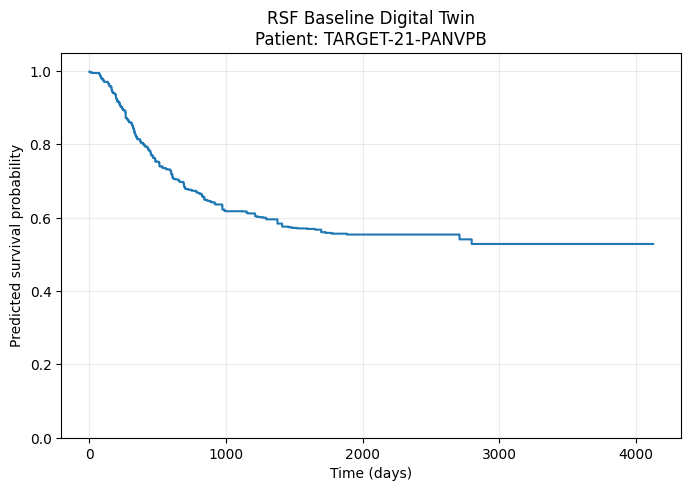

In [ ]:
patient_index = 0

rsf_fn = (
    rsf_survival_functions[
        patient_index
    ]
)


plt.figure(
    figsize=(8, 5)
)

plt.step(
    rsf_fn.x,
    rsf_fn.y,
    where="post"
)

plt.xlabel(
    "Time (days)"
)

plt.ylabel(
    "Predicted survival probability"
)

plt.title(
    f"RSF Baseline Digital Twin\n"
    f"Patient: {test_df.iloc[patient_index]['PATIENT_ID']}"
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    alpha=0.25
)

plt.show()

In [ ]:
patient = baseline_twins.iloc[0]


comparison = pd.DataFrame({

    "Time": [
        "1 Year",
        "2 Years",
        "3 Years"
    ],

    "RSF": [
        patient["RSF_SURVIVAL_1Y"],
        patient["RSF_SURVIVAL_2Y"],
        patient["RSF_SURVIVAL_3Y"]
    ],

    "XGBoost": [
        patient["XGB_SURVIVAL_1Y"],
        patient["XGB_SURVIVAL_2Y"],
        patient["XGB_SURVIVAL_3Y"]
    ]
})


display(
    comparison.round(4)
)

,Time,RSF,XGBoost
0,1 Year,0.8140,0.7870
1,2 Years,0.6763,0.6052
2,3 Years,0.6177,0.5401


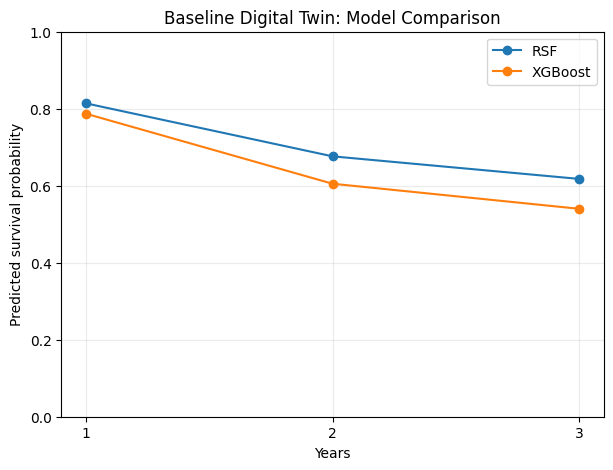

In [ ]:
times = [
    1,
    2,
    3
]

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    times,
    comparison["RSF"],
    marker="o",
    label="RSF"
)

plt.plot(
    times,
    comparison["XGBoost"],
    marker="o",
    label="XGBoost"
)

plt.xlabel(
    "Years"
)

plt.ylabel(
    "Predicted survival probability"
)

plt.title(
    "Baseline Digital Twin: Model Comparison"
)

plt.xticks(
    [1, 2, 3]
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()

In [ ]:
agreement_results = []

for horizon in [
    "1Y",
    "2Y",
    "3Y"
]:

    rsf_col = (
        f"RSF_SURVIVAL_{horizon}"
    )

    xgb_col = (
        f"XGB_SURVIVAL_{horizon}"
    )

    correlation = (
        baseline_twins[
            [rsf_col, xgb_col]
        ]
        .corr()
        .iloc[0, 1]
    )

    mean_absolute_difference = (
        np.abs(
            baseline_twins[rsf_col]
            -
            baseline_twins[xgb_col]
        )
        .mean()
    )

    agreement_results.append({

        "Horizon":
            horizon,

        "Correlation":
            correlation,

        "Mean_Absolute_Difference":
            mean_absolute_difference
    })


agreement_df = pd.DataFrame(
    agreement_results
)


display(
    agreement_df.round(4)
)

,Horizon,Correlation,Mean_Absolute_Difference
0,1Y,0.8635,0.0411
1,2Y,0.9019,0.0674
2,3Y,0.9031,0.0715


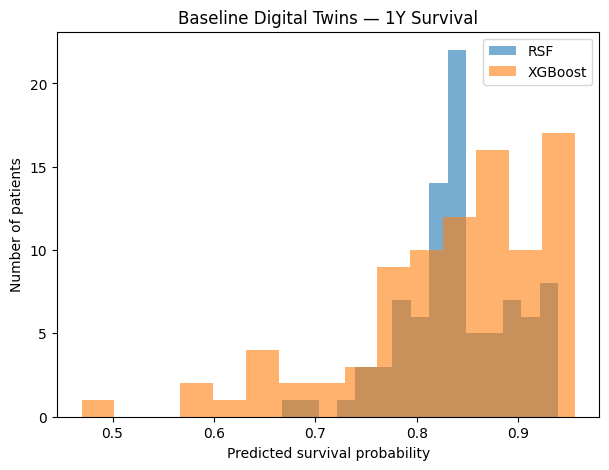

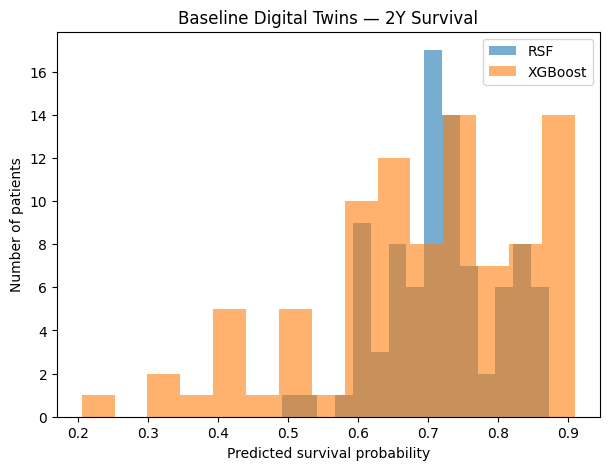

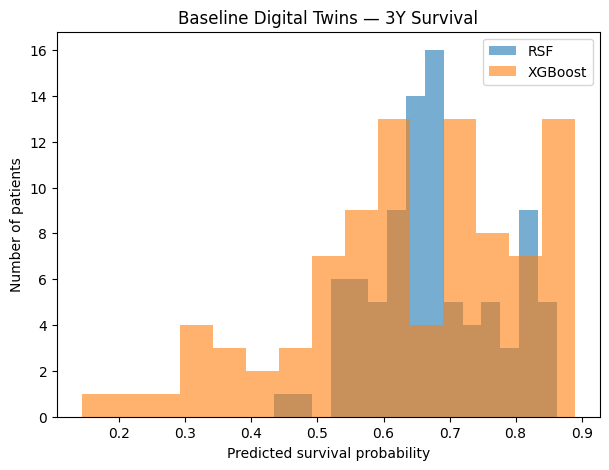

In [ ]:
for horizon in [
    "1Y",
    "2Y",
    "3Y"
]:

    plt.figure(
        figsize=(7, 5)
    )

    plt.hist(
        baseline_twins[
            f"RSF_SURVIVAL_{horizon}"
        ],
        bins=15,
        alpha=0.6,
        label="RSF"
    )

    plt.hist(
        baseline_twins[
            f"XGB_SURVIVAL_{horizon}"
        ],
        bins=15,
        alpha=0.6,
        label="XGBoost"
    )

    plt.xlabel(
        "Predicted survival probability"
    )

    plt.ylabel(
        "Number of patients"
    )

    plt.title(
        f"Baseline Digital Twins — {horizon} Survival"
    )

    plt.legend()

    plt.show()

In [ ]:
DIGITAL_TWIN_DIR = (
    BASE_DIR
    /
    "digital_twins"
)

DIGITAL_TWIN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OUTPUT_PATH = (
    DIGITAL_TWIN_DIR
    /
    "baseline_digital_twins.csv"
)


baseline_twins.to_csv(
    OUTPUT_PATH,
    index=False
)


print(
    "Saved to:",
    OUTPUT_PATH
)

Saved to: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/digital_twins/baseline_digital_twins.csv
